# Part 2 of 5: Models, Training & Tuning

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 7–9: the models, the training engine, hyperparameter tuning, ablations and the selection of the final models on the validation set.

The notebooks run in order: `01_data` → `02_models_and_tuning` → `03_test_evaluation` → `04_background_bias` → `05_generalisation`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plantdisease.config import SEEDS, out_path
from plantdisease.data import prepare
from plantdisease.experiments import (
    ALL_CONFIGS,
    TUNING_SEED,
    cnn_configs,
    resnet_configs,
    save_final_models,
    vit_configs,
)
from plantdisease.models import build_model, count_params
from plantdisease.plots import finish
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | ImageNet-pretrained Vision Transformer. The image is cut into 14×14 patches of 16×16 pixels, and 12 self-attention blocks relate every patch to every other patch (Lab 5). We fine-tune only the last 4 blocks and the new head, because the full 86 M-parameter model is expensive and easy to overfit on ~4k images. |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone (ResNet18: all layers; ViT: last 4 blocks) is unfrozen and trained with a smaller learning rate.

The models are defined in `plantdisease/models.py`.

In [13]:
for arch in ["cnn", "se_cnn"]:
    print(
        f"{arch:8s} parameters: {count_params(build_model({'arch': arch, 'dropout': 0.3})):,}"
    )

cnn      parameters: 389,924
se_cnn   parameters: 412,224


## 8. Training Engine

`run(name, cfg, seed, data)` (`plantdisease/train.py`) trains one configuration with one seed:
- **AdamW** (Adam with decoupled weight decay) and a **cosine learning-rate schedule**, stepped every batch, which decays the learning rate smoothly to zero in each stage;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning at `lr`;
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (early-stopping style model selection). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained.

The test set is never touched here.

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 to 9.3 use training seed 42 and are compared by the **best validation macro-F1**. Section 9.4 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

**9.3 ViT-B/16.** We use the two-stage recipe: 1 epoch for the head, then the last 4 blocks at lr 5e-5. ViT fine-tuning needs a smaller learning rate than CNNs, and the ViT is too expensive for a large sweep.

All configurations are defined in `plantdisease/experiments.py`.

In [15]:
histories = {
    name: run(name, cfg, TUNING_SEED, data) for name, cfg in cnn_configs.items()
}


===== SE-CNN (full recipe) (seed 42) =====
Epoch 1/50 [finetune] | train loss 0.5452 acc 0.8087 | val loss 0.2750 acc 0.8985 macro-F1 0.8825 | 33s
Epoch 2/50 [finetune] | train loss 0.3678 acc 0.8743 | val loss 0.3245 acc 0.8590 macro-F1 0.8066 | 31s
Epoch 3/50 [finetune] | train loss 0.2855 acc 0.9048 | val loss 0.1386 acc 0.9487 macro-F1 0.9426 | 31s
Epoch 4/50 [finetune] | train loss 0.2667 acc 0.9046 | val loss 0.1149 acc 0.9647 macro-F1 0.9599 | 31s
Epoch 5/50 [finetune] | train loss 0.2523 acc 0.9130 | val loss 0.1871 acc 0.9316 macro-F1 0.9237 | 31s
Epoch 6/50 [finetune] | train loss 0.2127 acc 0.9297 | val loss 0.1139 acc 0.9626 macro-F1 0.9589 | 31s
Epoch 7/50 [finetune] | train loss 0.1882 acc 0.9375 | val loss 0.1485 acc 0.9391 macro-F1 0.9299 | 31s
Epoch 8/50 [finetune] | train loss 0.1829 acc 0.9396 | val loss 0.1116 acc 0.9551 macro-F1 0.9454 | 31s
Epoch 9/50 [finetune] | train loss 0.1649 acc 0.9448 | val loss 0.1079 acc 0.9605 macro-F1 0.9549 | 31s
Epoch 10/50 [finetun

In [16]:
histories.update(
    {
        name: run(name, cfg, TUNING_SEED, data)
        for name, cfg in {**resnet_configs, **vit_configs}.items()
    }
)

Loaded finished run: ResNet18 frozen backbone (seed 42)
Loaded finished run: ResNet18 full FT, constant lr (seed 42)

===== ResNet18 two-stage + cosine, lr=1e-4 (seed 42) =====
Epoch 1/16 [head] | train loss 0.7438 acc 0.7586 | val loss 0.4587 acc 0.8825 macro-F1 0.8582 | 12s
Epoch 2/16 [finetune] | train loss 0.1630 acc 0.9563 | val loss 0.1072 acc 0.9786 macro-F1 0.9729 | 29s
Epoch 3/16 [finetune] | train loss 0.0588 acc 0.9835 | val loss 0.0578 acc 0.9882 macro-F1 0.9854 | 28s
Epoch 4/16 [finetune] | train loss 0.0394 acc 0.9920 | val loss 0.0576 acc 0.9893 macro-F1 0.9869 | 29s
Epoch 5/16 [finetune] | train loss 0.0305 acc 0.9911 | val loss 0.0574 acc 0.9882 macro-F1 0.9854 | 28s
Epoch 6/16 [finetune] | train loss 0.0169 acc 0.9946 | val loss 0.0423 acc 0.9904 macro-F1 0.9878 | 28s
Epoch 7/16 [finetune] | train loss 0.0214 acc 0.9946 | val loss 0.0626 acc 0.9861 macro-F1 0.9826 | 28s
Epoch 8/16 [finetune] | train loss 0.0169 acc 0.9955 | val loss 0.0700 acc 0.9861 macro-F1 0.9830 |

In [17]:
def summarize(name):
    h, cfg = histories[name], ALL_CONFIGS[name]
    best = int(np.argmax(h["val_f1"]))
    return {
        "run": name,
        "arch": cfg["arch"],
        "lr": cfg["lr"],
        "batch": cfg["batch_size"],
        "dropout": cfg["dropout"],
        "augment": cfg["augment"],
        "class_w": cfg["class_weights"],
        "schedule": cfg["scheduler"],
        "best_epoch": best + 1,
        "val_acc": h["val_acc"][best],
        "val_macro_f1": h["val_f1"][best],
        "sec_per_epoch": np.mean(h["epoch_time"]),
    }


tuning = pd.DataFrame([summarize(n) for n in histories]).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

Selected models: ['SE-CNN batch size 64', 'ResNet18 two-stage + cosine, lr=3e-4', 'ViT-B/16 two-stage + cosine']


,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,sec_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,43,0.9936,0.9926,31.2218
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,48,0.9947,0.9940,31.2291
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,36,0.9957,0.9954,31.1702
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,42,0.9925,0.9923,21.0916
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,50,0.9936,0.9931,28.9941
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,50,0.9947,0.9940,31.1853
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,43,0.9936,0.9926,31.1287
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,43,0.9936,0.9928,31.0772
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,45,0.9957,0.9954,31.3620


### 9.4 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 42) are therefore repeated with all training seeds, and the **final models are chosen by the mean validation macro-F1 over the seeds**. The ViT keeps its single configuration. The test set is not used here.


In [ ]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": cnn_configs, "resnet18": resnet_configs}
rows = []
for family, configs in families.items():
    top = tuning.loc[list(configs), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = np.array(
            [max(run(name, configs[name], seed, data)["val_f1"]) for seed in SEEDS]
        )
        rows.append(
            {
                "family": family,
                "run": name,
                "val macro-F1 (seed 42)": tuning.at[name, "val_macro_f1"],
                "mean over seeds": scores.mean(),
                "std": scores.std(ddof=1) if len(scores) > 1 else 0.0,
                "min": scores.min(),
                "max": scores.max(),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

BEST_CNN = multi_seed.loc[multi_seed.family == "cnn", "mean over seeds"].idxmax()
BEST_RESNET = multi_seed.loc[
    multi_seed.family == "resnet18", "mean over seeds"
].idxmax()
BEST_VIT = next(iter(vit_configs))
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
save_final_models(*FINAL_MODELS)  # OUT_DIR/final_models.json, read by notebooks 03-05
print("Selected models:", FINAL_MODELS)
multi_seed.round(4)

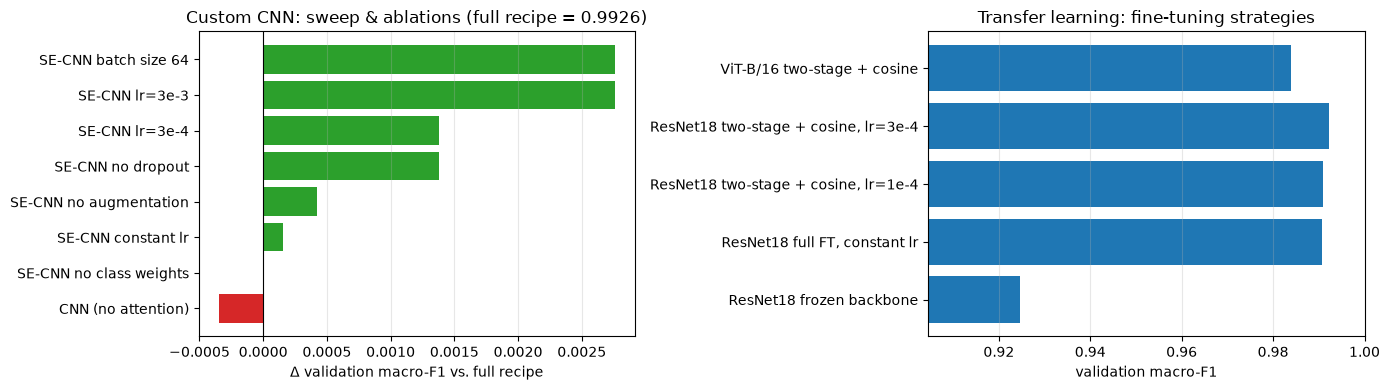

In [18]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(cnn_configs)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(resnet_configs) + list(vit_configs), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("Transfer learning: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

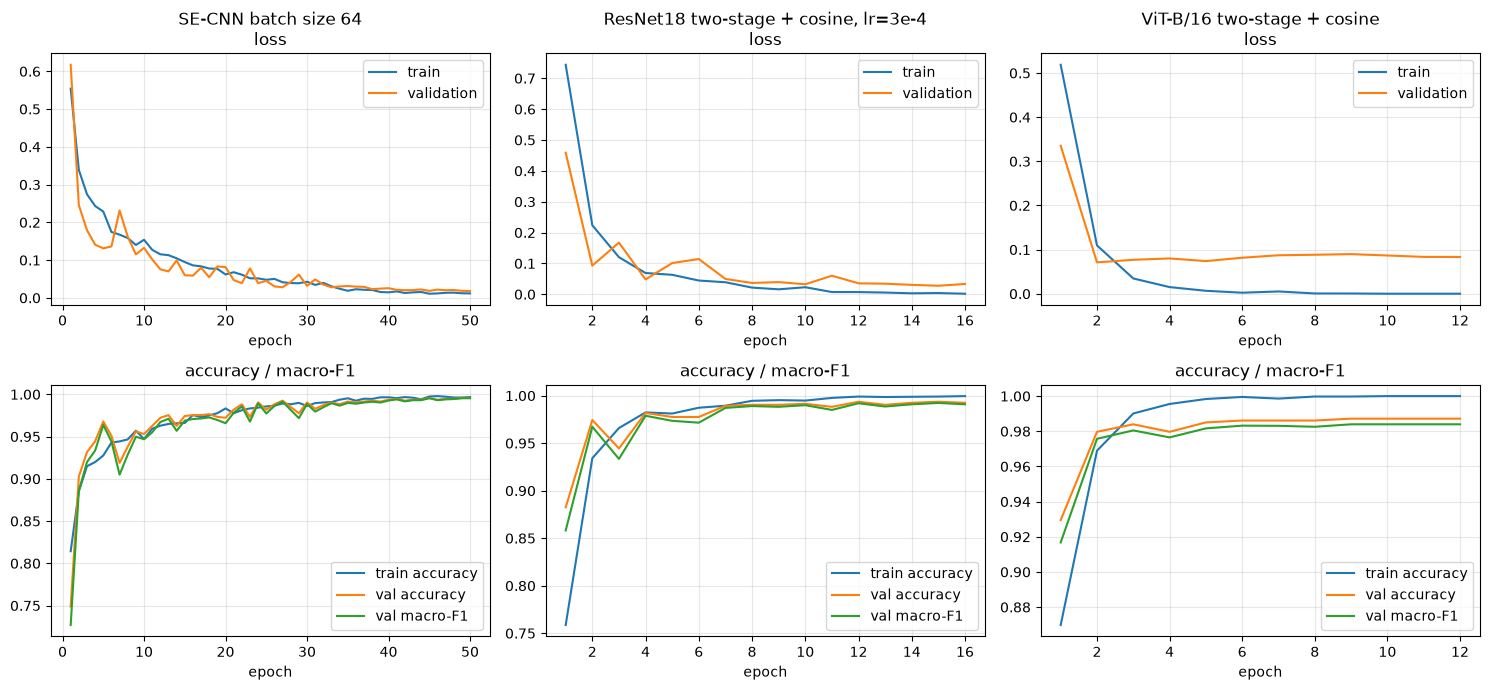

In [19]:
# Learning curves of the selected models (seed 42)
fig, axes = plt.subplots(2, len(FINAL_MODELS), figsize=(5 * len(FINAL_MODELS), 7))
for col, name in enumerate(FINAL_MODELS):
    h = histories[name]
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[0, col].plot(epochs, h["train_loss"], label="train")
    axes[0, col].plot(epochs, h["val_loss"], label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h["train_acc"], label="train accuracy")
    axes[1, col].plot(epochs, h["val_acc"], label="val accuracy")
    axes[1, col].plot(epochs, h["val_f1"], label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")